# 05 — Single Sérsic mock-pipeline validation, noisy observation

Question: when realistic pipeline ingredients include sky, background subtraction, empirical noise estimation, known Gaussian PSF, and noisy image data, does the full BayMorph pipeline remain stable?


## Validation logic

This notebook is intentionally narrow. It tests one additional layer of complexity relative to the previous notebook. The goal is not to make a pretty demo; the goal is to know exactly where a discrepancy first appears.

BayMorph mask convention: `mask=True` means excluded pixel.


In [1]:

from pathlib import Path
import json
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

from baymorph.models import SersicModel
from baymorph.simulation.psf import GaussianPSF, convolve_with_psf
from baymorph.pipeline.config import load_resolved_config
from baymorph.pipeline.image_preparation import prepare_real_image_from_config, load_image_preparation_products
from baymorph.pipeline.real_fit import run_real_fit_from_config


def show_image_triplet(a, b, c, titles):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, img, title in zip(axes, [a, b, c], titles):
        im = ax.imshow(img, origin="lower")
        ax.set_title(title)
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()


def compare_truth(best_parameters, truth):
    rows = []
    for k in ["flux", "re", "n", "q", "theta", "x0", "y0", "sky"]:
        if k not in best_parameters:
            continue
        tv = truth.get(k, 0.0 if k == "sky" else np.nan)
        bv = best_parameters[k]
        if k == "theta":
            tv = np.rad2deg(tv)
            bv = np.rad2deg(bv)
            unit = "deg"
        else:
            unit = ""
        rows.append({"parameter": k, "truth": tv, "best_ML": bv, "best_minus_truth": bv - tv, "unit": unit})
    return pd.DataFrame(rows)

from baymorph.simulation.noise import add_gaussian_noise


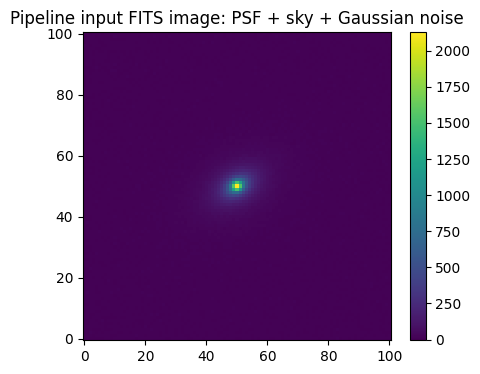

In [2]:

workdir = Path("validation_outputs/05_mock_pipeline_noisy")
workdir.mkdir(parents=True, exist_ok=True)

shape = (101, 101)
psf_fwhm = 2.0
noise_sigma = 3.0
sky_true = 5.0
truth = {
    "flux": 1.0e5,
    "re": 8.0,
    "n": 2.0,
    "q": 0.65,
    "theta": np.deg2rad(30.0),
    "x0": 50.0,
    "y0": 50.0,
    "sky": sky_true,
}

intrinsic = SersicModel(**{k: truth[k] for k in ["flux", "re", "n", "q", "theta", "x0", "y0"]}).render(shape)
clean = convolve_with_psf(intrinsic, GaussianPSF(psf_fwhm)) + sky_true
image = add_gaussian_noise(clean, sigma=noise_sigma, seed=47)
image_path = workdir / "mock_single_sersic_psf_gaussian_noise.fits"
fits.writeto(image_path, image, overwrite=True)

plt.figure(figsize=(5,4))
plt.imshow(image, origin="lower")
plt.colorbar()
plt.title("Pipeline input FITS image: PSF + sky + Gaussian noise")
plt.show()


In [3]:

config = {
    "object": {"name": "mock_single_sersic_pipeline_noisy"},
    "data": {
        "image_path": str(image_path),
        "target_position": {"x": 50, "y": 50},
        "cutout": {"mode": "fixed", "size": 101},
    },
    "outputs": {"root": str(workdir / "outputs"), "overwrite": True},
    "preparation": {
        "background": {"method": "empirical", "box_size": 30, "filter_size": 3},
        "noise": {"method": "empirical"},
        "detection": {"n_sigma": 2.0, "n_levels": 32, "npixels": 10},
    },
    "masking": {
        "connected_source": {"enabled": True},
        "star_halo": {"enabled": False},
        "interactive_refinement": {"enabled": False},
    },
    "psf": {"type": "gaussian", "gaussian": {"fwhm": psf_fwhm}},
    "fit": {
        "models": ["single_sersic"],
        "sampler": {"name": "dynesty", "nlive": 350, "sample": "rwalk", "dlogz": 0.1, "seed": 48, "n_processes": 1},
        "priors": {
            "single_sersic": {
                "flux": {"min_factor": 0.7, "max_factor": 1.3},
                "re": {"min": 5.0, "max": 11.0},
                "n": {"min": 1.0, "max": 3.5},
                "q": {"min": 0.45, "max": 0.85},
                "theta": {"min": "-pi/2", "max": "pi/2"},
                "x0": {"offset": 2.0},
                "y0": {"offset": 2.0},
                "sky": {"min": -10.0, "max": 10.0},
            }
        },
    },
    "diagnostics": {"format": "pdf", "corner": True, "residual": True, "radial_profile": True, "posterior_profile_bands": False},
}

config_path = workdir / "config_mock_pipeline_noisy.yaml"
with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)
print(config_path)


validation_outputs/05_mock_pipeline_noisy/config_mock_pipeline_noisy.yaml


true sky: 5.0
background estimated/subtracted: 5.228255397579414
true injected sigma: 3.0
estimated noise median: 2.9844603486118144
target label: 1
masked fraction: 0.0


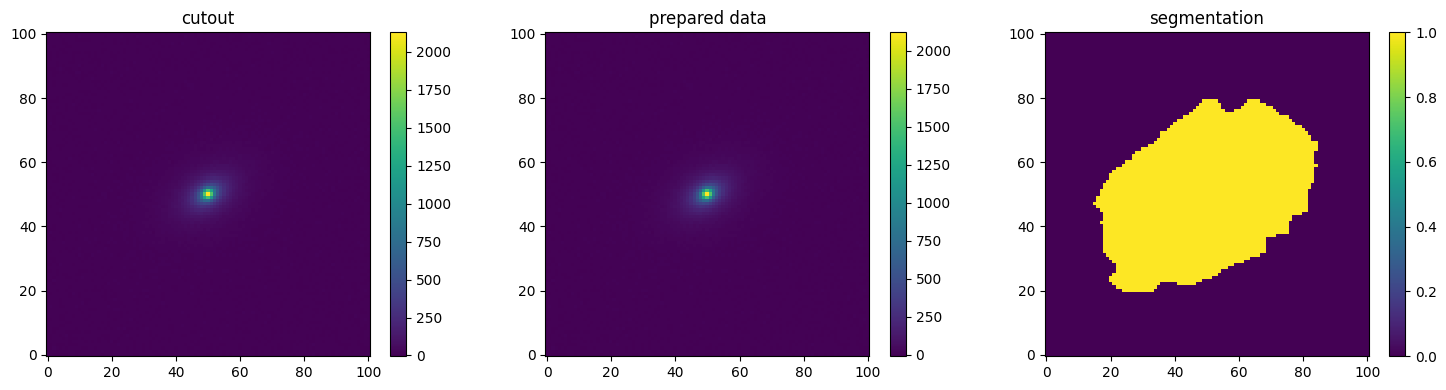

In [4]:

resolved = load_resolved_config(config_path)
prep = prepare_real_image_from_config(resolved, save=True)
print("true sky:", sky_true)
print("background estimated/subtracted:", prep.background)
print("true injected sigma:", noise_sigma)
print("estimated noise median:", np.nanmedian(prep.noise))
print("target label:", prep.target_label)
print("masked fraction:", np.mean(prep.contaminant_mask))
show_image_triplet(prep.cutout, prep.prepared_data, prep.segmentation, ["cutout", "prepared data", "segmentation"])


iter: 18656 | +350 | bound: 53 | nc: 1 | ncall: 501214 | eff(%):  3.795 | loglstar:   -inf < -25727.434 <    inf | logz: -25778.364 +/-  0.369 | dlogz:  0.000 >  0.100                               

,parameter,truth,best_ML,best_minus_truth,unit
0,flux,100000.00,99974.451333,-25.548667,
1,re,8.00,8.007605,0.007605,
2,n,2.00,2.006733,0.006733,
3,q,0.65,0.648939,-0.001061,
4,theta,30.00,29.990280,-0.009720,deg
5,x0,50.00,49.999962,-0.000038,
6,y0,50.00,49.999913,-0.000087,
7,sky,0.00,-0.245448,-0.245448,


chi2: 10398.751523796354
reduced chi2: 1.020185570861999


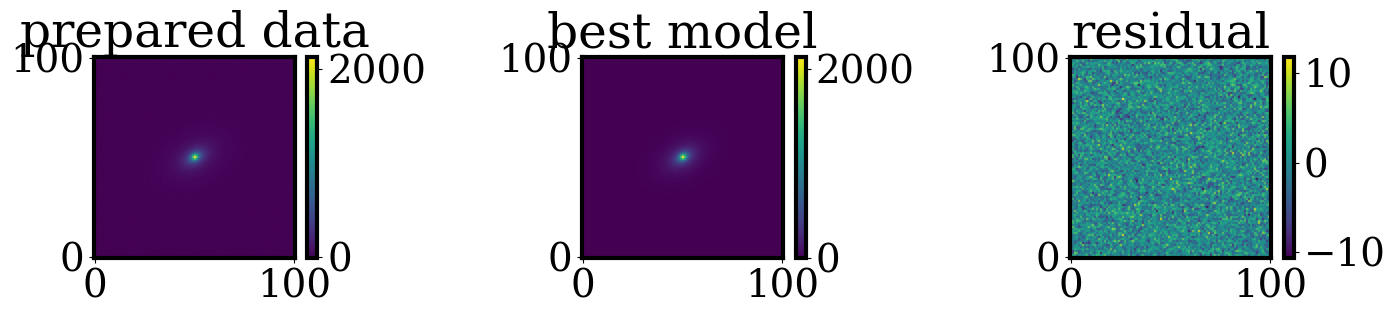

In [5]:

products = run_real_fit_from_config(resolved)
fit = products["single_sersic"]
# The fitted sky is sky relative to the background-subtracted prepared_data, not the original sky_true.
display(compare_truth(fit.best_parameters, {**truth, "sky": 0.0}))
print("chi2:", fit.chi2)
print("reduced chi2:", fit.reduced_chi2)
show_image_triplet(prep.prepared_data, fit.best_model_image, fit.residual, ["prepared data", "best model", "residual"])

assert abs(fit.best_parameters["x0"] - truth["x0"]) < 0.8
assert abs(fit.best_parameters["y0"] - truth["y0"]) < 0.8
assert abs(fit.best_parameters["theta"] - truth["theta"]) < np.deg2rad(8.0)
